# 01 · Data Analysis: LRU vs LFU под нагрузкой Zipf

**TASK 3 — Результаты исследования, анализ данных и научная визуализация.**

Ноутбук воспроизводимо превращает сырые замеры `data/raw/test_run.jsonl` (собраны `python -m src.collect`)
в агрегированную таблицу `data/processed/metrics_summary.csv` и графики `reports/figures/`.
Вся логика вынесена в модули `src/process_data.py` и `src/visualize.py`; здесь — только вызовы и интерпретация.

**Гипотеза.** H1: при Zipf α = 1.0 и размере кэша 100 (1 % ключей) относительный прирост Hit Rate LFU над LRU ≥ 15 %.
H0 отвергается, если нижняя граница 95 % бутстреп-CI прироста ≥ 15 %.

Структура:
1. Setup и фиксация случайности
2. Data Ingestion & Warm-up Filtering
3. Guardrail-метрики (ошибки, ёмкость кэша)
4. Statistical Aggregation (медиана, p95, p99, Mean ± SD, 95 % CI)
5. Проверка гипотезы H1
6. Анализ точки безубыточности по задержке
7. Visualization & Export
8. Выводы

## 1. Setup и фиксация случайности

In [1]:
import os, sys, platform
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

# корень репозитория: ноутбук запускается из notebooks/ или из корня
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

from src import process_data as pdp
from src import visualize as viz

SEED = 42
np.random.seed(SEED)            # глобальный seed (на случай сторонних вызовов)
rng = np.random.default_rng(SEED)  # все бутстрепы используют seed=SEED явно
pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 3)

RAW = ROOT / "data/raw/test_run.jsonl"
PROCESSED = ROOT / "data/processed"
FIGURES = ROOT / "reports/figures"
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__)
print("Raw log:", RAW.relative_to(ROOT), f"({RAW.stat().st_size / 1e6:.1f} MB)")

Python 3.13.18 | numpy 2.4.4 | pandas 3.1.1
Raw log: data/raw/test_run.jsonl (6.9 MB)


## 2. Data Ingestion & Warm-up Filtering

Каждая строка JSONL — окно из 5 000 запросов одного прогона (политика × размер кэша × α × seed).
Первая строка — `meta` (окружение и конфиг). Окна, начавшиеся в первых 20 % запросов, помечены `phase = "warmup"`:
кэш ещё «холодный», и их Hit Rate систематически занижен.

In [2]:
meta, windows = pdp.load_raw(RAW)
print("Собрано:", meta["created_utc"], "| Python", meta["python"], "|", meta["platform"])
print("Backend:", meta["config"]["backend"], "| warm-up fraction:", meta["config"]["experiment"]["warmup_fraction"])
print(f"Окон: {len(windows)}, прогонов: {windows.run_id.nunique()}, запросов: {windows.n.sum():,}")
windows.groupby("phase").agg(windows=("run_id", "size"), requests=("n", "sum"))

Собрано: 2026-11-05T13:59:57+00:00 | Python 3.13.18 | Linux-6.18.44-fc-v236-x86_64-with-glibc2.39
Backend: {'type': 'sqlite'} | warm-up fraction: 0.2
Окон: 6000, прогонов: 300, запросов: 30,000,000


,windows,requests
phase,,
benchmark,4800,24000000
warmup,1200,6000000


In [3]:
windows.drop(columns="lat_sample_ms").head(3)

,record,run_id,policy,cache_size,alpha,seed,window,req_start,phase,n,hits,errors,cache_len,capacity_ok,lat_sum_ms,lat_p50_ms,lat_p95_ms,lat_p99_ms,lat_max_ms,wall_s
0,window,a0.0_c100_lru_s0,lru,100,0.0,0,0,0,warmup,5000,51,0,100,True,17.133,0.003,0.004,0.008,0.051,0.018
1,window,a0.0_c100_lru_s0,lru,100,0.0,0,1,5000,warmup,5000,46,0,100,True,16.370,0.003,0.004,0.007,0.051,0.018
2,window,a0.0_c100_lru_s0,lru,100,0.0,0,2,10000,warmup,5000,41,0,100,True,11.774,0.002,0.003,0.005,0.357,0.013


Насколько искажает результат отсутствие отсечки прогрева? Сравним Hit Rate по всем окнам и только по фазе benchmark:

In [4]:
hr = lambda d: 100 * d.hits.sum() / d.n.sum()
bias = (windows.groupby(["alpha", "cache_size", "policy"])
        .apply(lambda g: pd.Series({"HR_all_windows": hr(g),
                                    "HR_benchmark_only": hr(g[g.phase == "benchmark"])}),
               include_groups=False)
        .assign(bias_pp=lambda d: d.HR_all_windows - d.HR_benchmark_only))
bias.loc[1.0]

HR_all_windows  HR_benchmark_only  bias_pp
cache_size policy                                            
100        lfu             49.791             49.984   -0.193
           lru             39.020             39.016    0.005
500        lfu             65.778             66.366   -0.587
           lru             58.587             58.707   -0.120
1000       lfu             72.525             73.367   -0.841
           lru             67.326             67.596   -0.270

In [5]:
bench = pdp.filter_warmup(windows)
print(f"После отсечки warm-up: {len(bench)} окон, {bench.n.sum():,} запросов "
      f"({100 * bench.n.sum() / windows.n.sum():.0f} % исходных)")

После отсечки warm-up: 4800 окон, 24,000,000 запросов (80 % исходных)


**Вывод.** Без отсечки Hit Rate занижается до ~0.8 п.п. (сильнее всего у больших кэшей, которым нужно больше запросов на
заполнение). У LFU смещение в несколько раз больше, чем у LRU (LFU дольше накапливает счётчики частоты), — то есть прогрев
систематически занижал бы именно разницу между методами. Рис. 5 ниже
показывает, что к 20 000-му запросу оба кэша выходят на плато.

## 3. Guardrail-метрики

Метрики-ограничители, которые не должны ухудшаться независимо от результата основной метрики:
* **Error rate** — доля запросов, завершившихся исключением или вернувших неверный payload (каждый ответ сверяется с БД);
* **Capacity** — кэш ни в одном окне не превысил заданную ёмкость.

In [6]:
guard = pdp.check_guardrails(windows)
display(pd.Series(guard, name="value").to_frame())
assert guard["passed"], "Guardrail violated — results are not valid"

,value
total_requests,30000000
errors,0
error_rate_pct,0.0
capacity_violations,0
passed,True


## 4. Statistical Aggregation

Для каждого прогона (по benchmark-окнам) считаем точный Hit Rate и среднюю задержку (по всем 80 000 запросам),
а p50 / p95 / p99 — по случайной выборке 100 задержек на окно (1 600 на прогон, 16 000 на условие).
Затем по 10 seed-ам: Mean ± SD и 95 % перцентильный бутстреп-CI (10 000 ресэмплов, `seed=42`).

In [7]:
runs = pdp.per_run_metrics(bench)
samples = pdp.latency_samples(bench)
print(f"{len(runs)} прогонов, {len(samples):,} отсчётов задержки")
runs.head()

300 прогонов, 480,000 отсчётов задержки


,alpha,cache_size,policy,seed,requests,hit_rate,lat_mean_us,lat_p50_us,lat_p95_us,lat_p99_us,throughput_rps,error_rate,capacity_ok
0,0.0,100,lfu,0,80000,1.014,2.830,2.41,3.920,6.501,331607.592,0.0,True
1,0.0,100,lfu,1,80000,0.929,2.729,2.48,3.861,6.074,343107.611,0.0,True
2,0.0,100,lfu,2,80000,1.001,3.020,2.57,4.500,10.585,309546.012,0.0,True
3,0.0,100,lfu,3,80000,0.984,2.936,2.51,4.320,7.610,319240.208,0.0,True
4,0.0,100,lfu,4,80000,1.005,2.646,2.36,3.840,5.601,352803.687,0.0,True


In [8]:
summary = pdp.aggregate(runs, samples, seed=SEED)
gains = pdp.paired_gains(runs, seed=SEED)
PROCESSED.mkdir(parents=True, exist_ok=True)
summary.to_csv(PROCESSED / "metrics_summary.csv", index=False, float_format="%.6g")
gains.to_csv(PROCESSED / "paired_gains.csv", index=False, float_format="%.6g")
print("Saved:", (PROCESSED / "metrics_summary.csv").relative_to(ROOT), summary.shape)
summary[["alpha", "cache_size", "policy", "hit_rate_mean", "hit_rate_sd", "hit_rate_ci95_lo", "hit_rate_ci95_hi",
         "lat_pooled_median_us", "lat_pooled_p95_us", "lat_pooled_p99_us",
         "lat_mean_us_mean", "lat_mean_us_ci95_lo", "lat_mean_us_ci95_hi"]]

Saved: data/processed/metrics_summary.csv (30, 32)


,alpha,cache_size,policy,hit_rate_mean,hit_rate_sd,hit_rate_ci95_lo,hit_rate_ci95_hi,lat_pooled_median_us,lat_pooled_p95_us,lat_pooled_p99_us,lat_mean_us_mean,lat_mean_us_ci95_lo,lat_mean_us_ci95_hi
0,0.0,100,lfu,0.969,0.036,0.948,0.990,2.460,4.17,7.700,2.819,2.651,3.003
1,0.0,100,lru,1.006,0.025,0.991,1.020,2.060,3.76,5.811,2.504,2.267,2.836
2,0.0,500,lfu,4.971,0.080,4.922,5.015,2.460,4.38,7.130,2.916,2.771,3.086
3,0.0,500,lru,5.014,0.075,4.970,5.059,2.090,3.69,6.501,2.410,2.228,2.614
4,0.0,1000,lfu,9.937,0.096,9.875,9.985,2.390,3.98,6.721,2.576,2.441,2.724
5,0.0,1000,lru,10.016,0.086,9.962,10.065,2.050,3.60,6.040,2.250,2.133,2.366
6,0.6,100,lfu,10.400,0.513,10.083,10.679,2.460,3.97,6.810,2.638,2.547,2.730
7,0.6,100,lru,4.322,0.058,4.288,4.356,2.050,3.62,6.400,2.476,2.265,2.716
8,0.6,500,lfu,22.795,0.289,22.626,22.967,2.470,4.47,6.910,2.675,2.397,3.011
9,0.6,500,lru,15.182,0.147,15.094,15.265,2.060,3.65,6.091,2.256,2.064,2.463


Парное сравнение (одна и та же трасса для обеих политик в каждом seed): относительный прирост Hit Rate и изменение средней задержки LFU относительно LRU.

In [9]:
gains

,alpha,cache_size,n_pairs,delta_hit_pp,rel_gain_pct,rel_gain_ci95_lo,rel_gain_ci95_hi,rel_latency_change_pct,rel_latency_ci95_lo,rel_latency_ci95_hi,lfu_wins_seeds
0,0.0,100,10,-0.037,-3.597,-5.615,-1.297,14.966,4.822,24.045,2
1,0.0,500,10,-0.043,-0.850,-1.953,0.125,22.590,12.562,31.270,3
2,0.0,1000,10,-0.079,-0.780,-1.477,-0.139,15.038,7.709,21.567,3
3,0.6,100,10,6.078,140.680,133.269,147.638,8.229,0.430,16.088,10
4,0.6,500,10,7.612,50.153,48.719,51.531,18.793,10.077,28.885,10
5,0.6,1000,10,7.470,30.655,29.830,31.494,25.417,13.025,37.197,10
6,0.8,100,10,10.621,67.697,65.852,69.576,15.703,7.447,22.873,10
7,0.8,500,10,9.575,28.920,28.595,29.255,24.433,4.120,47.118,10
8,0.8,1000,10,8.183,18.743,18.552,18.961,21.593,11.340,31.650,10
9,1.0,100,10,10.968,28.115,27.275,28.949,20.427,15.558,23.921,10


Итоговая таблица Baseline (LRU) vs Proposed (LFU) для основного условия α = 1.0 (она же вставлена в README):

In [10]:
table = pdp.results_table(summary, gains, alpha=1.0)
display(Markdown(pdp.to_markdown(table)))

| Cache size | Method | Hit Rate, % (Mean ± SD) | Latency, µs Median (p25–p75) | p95, µs | p99, µs | Mean latency, µs [95% CI] | Rel. HR gain, % [95% CI] | Errors, % |
|---|---|---|---|---|---|---|---|---|
| 100 | LRU (baseline) | 39.02 ± 0.12 | 1.90 (0.36–2.25) | 3.50 | 5.79 | 1.72 [1.54, 1.92] | — | 0.00 |
| 100 | LFU (proposed) | 49.98 ± 0.50 | 2.14 (0.84–2.67) | 4.14 | 6.17 | 2.07 [1.86, 2.31] | +28.1 [+27.3, +28.9] | 0.00 |
| 500 | LRU (baseline) | 58.71 ± 0.16 | 0.44 (0.28–2.04) | 3.35 | 4.48 | 1.25 [1.14, 1.39] | — | 0.00 |
| 500 | LFU (proposed) | 66.37 ± 0.27 | 1.15 (0.79–2.52) | 4.15 | 6.04 | 1.79 [1.58, 2.02] | +13.0 [+12.8, +13.3] | 0.00 |
| 1000 | LRU (baseline) | 67.60 ± 0.18 | 0.41 (0.28–1.99) | 3.45 | 4.29 | 1.12 [0.99, 1.28] | — | 0.00 |
| 1000 | LFU (proposed) | 73.37 ± 0.25 | 0.93 (0.75–2.26) | 3.63 | 5.37 | 1.53 [1.41, 1.70] | +8.5 [+8.4, +8.7] | 0.00 |

## 5. Проверка гипотезы H1

In [11]:
h1 = pdp.evaluate_h1(gains, alpha=1.0, cache_size=100, threshold=15.0)
lo, hi = h1["ci95"]
print(f"Relative gain = {h1['rel_gain_pct']:.2f} %  (95 % CI {lo:.2f} … {hi:.2f} %)")
print("H0 rejected:", h1["H0_rejected"])

Relative gain = 28.11 %  (95 % CI 27.28 … 28.95 %)
H0 rejected: True


In [12]:
# устойчивость вывода: в каких условиях нижняя граница CI выше 15 %?
gains.assign(above_15=gains.rel_gain_ci95_lo >= 15).pivot(index="alpha", columns="cache_size", values="above_15")

cache_size,100,500,1000
alpha,,,
0.0,False,False,False
0.6,True,True,True
0.8,True,True,True
1.0,True,False,False
1.2,False,False,False


## 6. Анализ точки безубыточности по задержке

Измеренная задержка (Рис. 1) показывает обратную картину: LFU **медленнее** LRU на 8–68 %, хотя промахов у него меньше.
Причина — бэкенд: SQLite в памяти отвечает за ~3 µs, это сопоставимо со стоимостью ведения частотных бакетов LFU в Python.
В реальной системе промах — это сетевой запрос к БД. Модель:

$$E[T_p] = T^{\text{meas}}_p + (1 - HR_p)\cdot t_{db}, \qquad
t_{db}^{*} = \frac{T^{\text{meas}}_{LFU} - T^{\text{meas}}_{LRU}}{HR_{LFU} - HR_{LRU}}$$

LFU выигрывает по задержке, как только штраф промаха $t_{db}$ превышает $t_{db}^{*}$.

In [13]:
be = pdp.break_even(summary, db_extra_ms=5.0)
be

,alpha,cache_size,measured_overhead_lfu_minus_lru_us,breakeven_db_penalty_us,modelled_lru_ms@5ms,modelled_lfu_ms@5ms,modelled_latency_change_pct
0,0.0,100,0.315,inf,4.952,4.954,0.043
1,0.0,500,0.506,inf,4.752,4.754,0.056
2,0.0,1000,0.326,inf,4.501,4.506,0.095
3,0.6,100,0.162,2.660,4.786,4.483,-6.346
4,0.6,500,0.420,5.512,4.243,3.863,-8.960
5,0.6,1000,0.480,6.422,3.783,3.410,-9.860
6,0.8,100,0.287,2.706,4.218,3.687,-12.584
7,0.8,500,0.390,4.073,3.346,2.868,-14.295
8,0.8,1000,0.320,3.913,2.819,2.410,-14.506
9,1.0,100,0.348,3.171,3.051,2.503,-17.964


In [14]:
finite = be[np.isfinite(be.breakeven_db_penalty_us)]
print(f"Точка безубыточности: от {finite.breakeven_db_penalty_us.min():.1f} до {finite.breakeven_db_penalty_us.max():.1f} µs "
      f"(при α > 0). Типичный сетевой round-trip к БД: 100–5000 µs.")

Точка безубыточности: от 2.7 до 16.6 µs (при α > 0). Типичный сетевой round-trip к БД: 100–5000 µs.


## 7. Visualization & Export

Все графики строятся функциями `src/visualize.py` и сохраняются в двух форматах: `.pdf` (вектор) и `.png` (300 DPI).
Палитра — `seaborn colorblind`; серии различаются ещё и маркерами/типом линии (или штриховкой у боксплотов).

In [15]:
viz.set_style()
paths = []
paths += viz.fig1_latency_vs_load(summary, FIGURES)
paths += viz.fig2_distribution_boxplot(samples, FIGURES, alpha=1.0)
paths += viz.fig3_hit_rate_vs_alpha(summary, FIGURES)
paths += viz.fig4_relative_gain(gains, FIGURES)
paths += viz.fig5_warmup(pdp.warmup_profile(windows), FIGURES, alpha=1.0)
for p in paths:
    print(f"{p.relative_to(ROOT)}  ({p.stat().st_size / 1024:.0f} KB)")

reports/figures/fig1_latency_vs_load.pdf  (19 KB)
reports/figures/fig1_latency_vs_load.png  (213 KB)
reports/figures/fig2_distribution_boxplot.pdf  (27 KB)
reports/figures/fig2_distribution_boxplot.png  (103 KB)
reports/figures/fig3_hit_rate_vs_alpha.pdf  (19 KB)
reports/figures/fig3_hit_rate_vs_alpha.png  (178 KB)
reports/figures/fig4_relative_gain.pdf  (28 KB)
reports/figures/fig4_relative_gain.png  (148 KB)
reports/figures/fig5_warmup_phase.pdf  (21 KB)
reports/figures/fig5_warmup_phase.png  (146 KB)


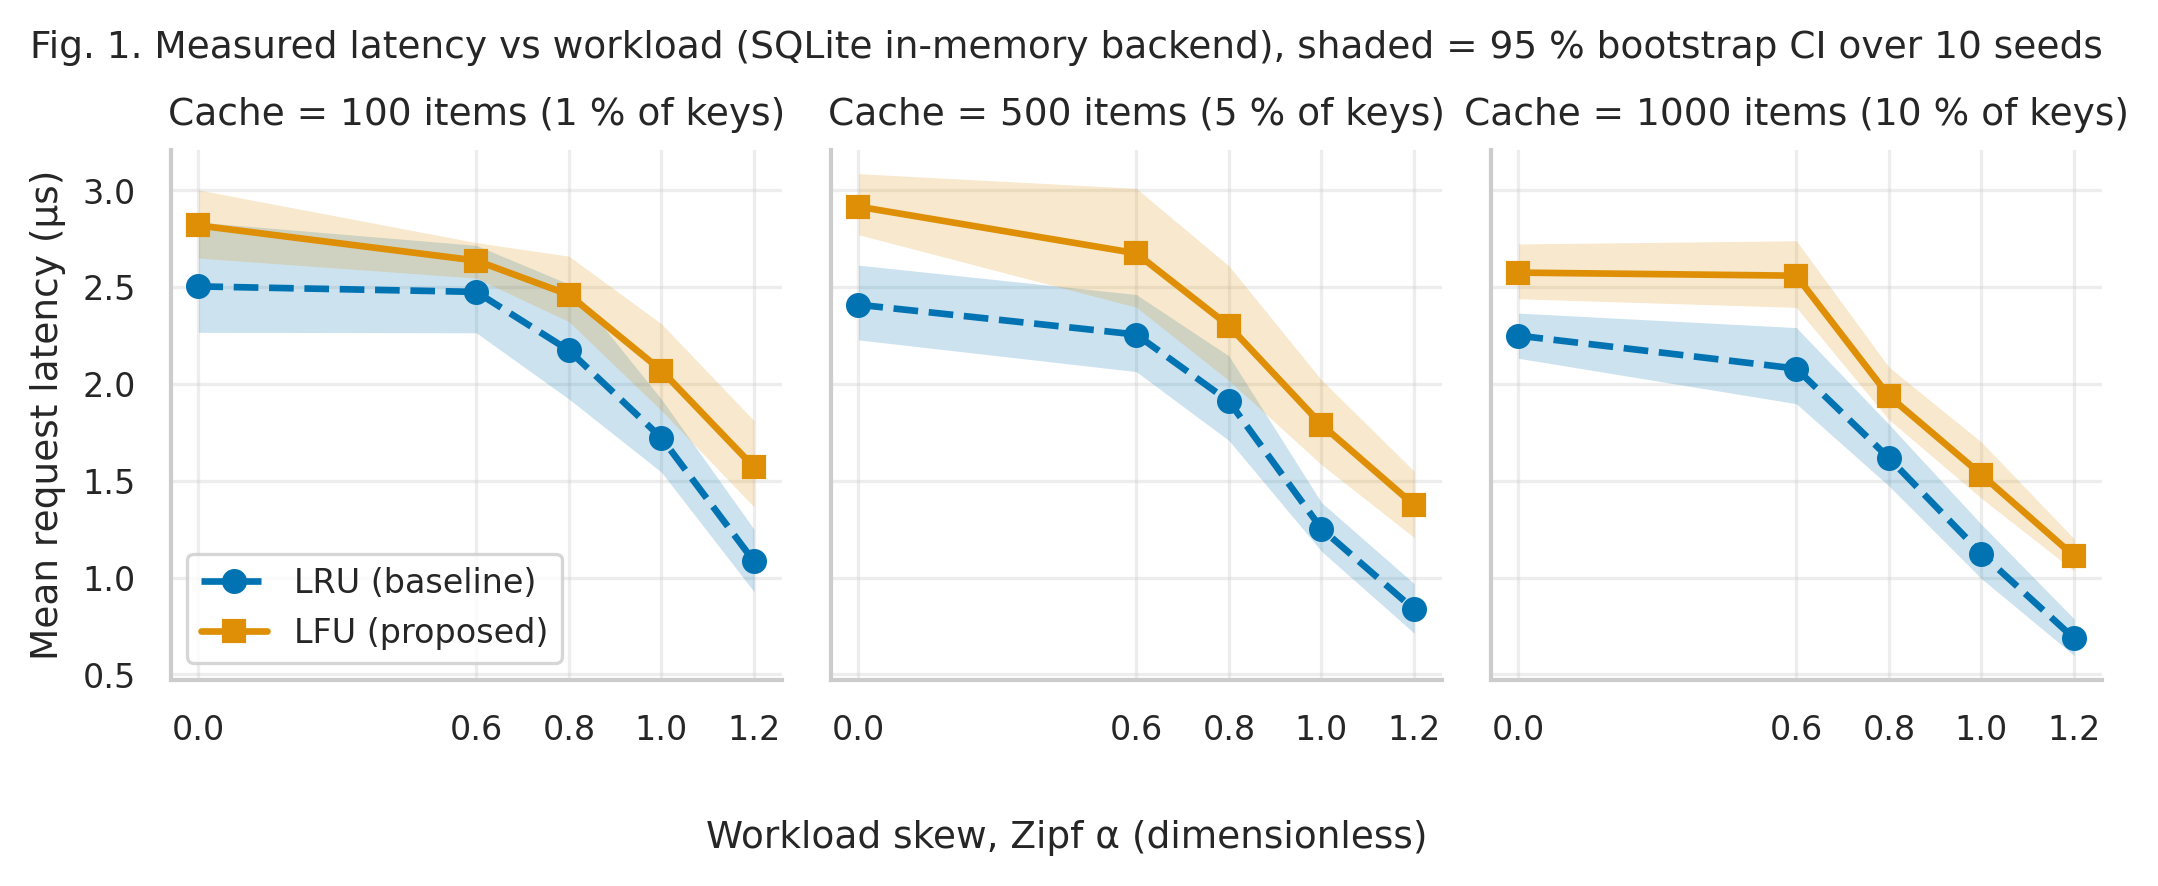

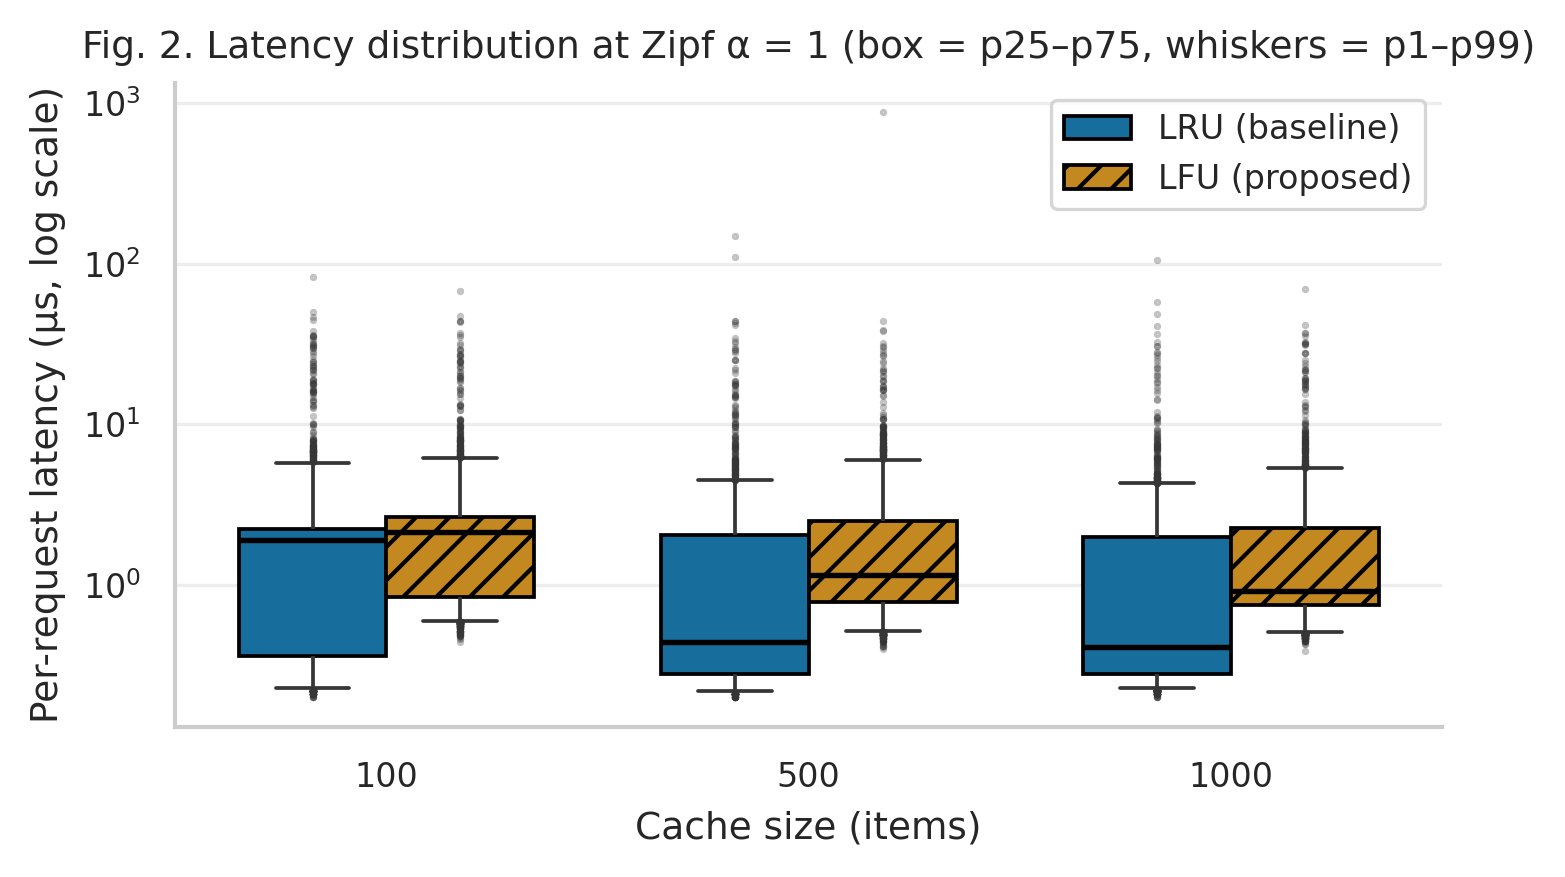

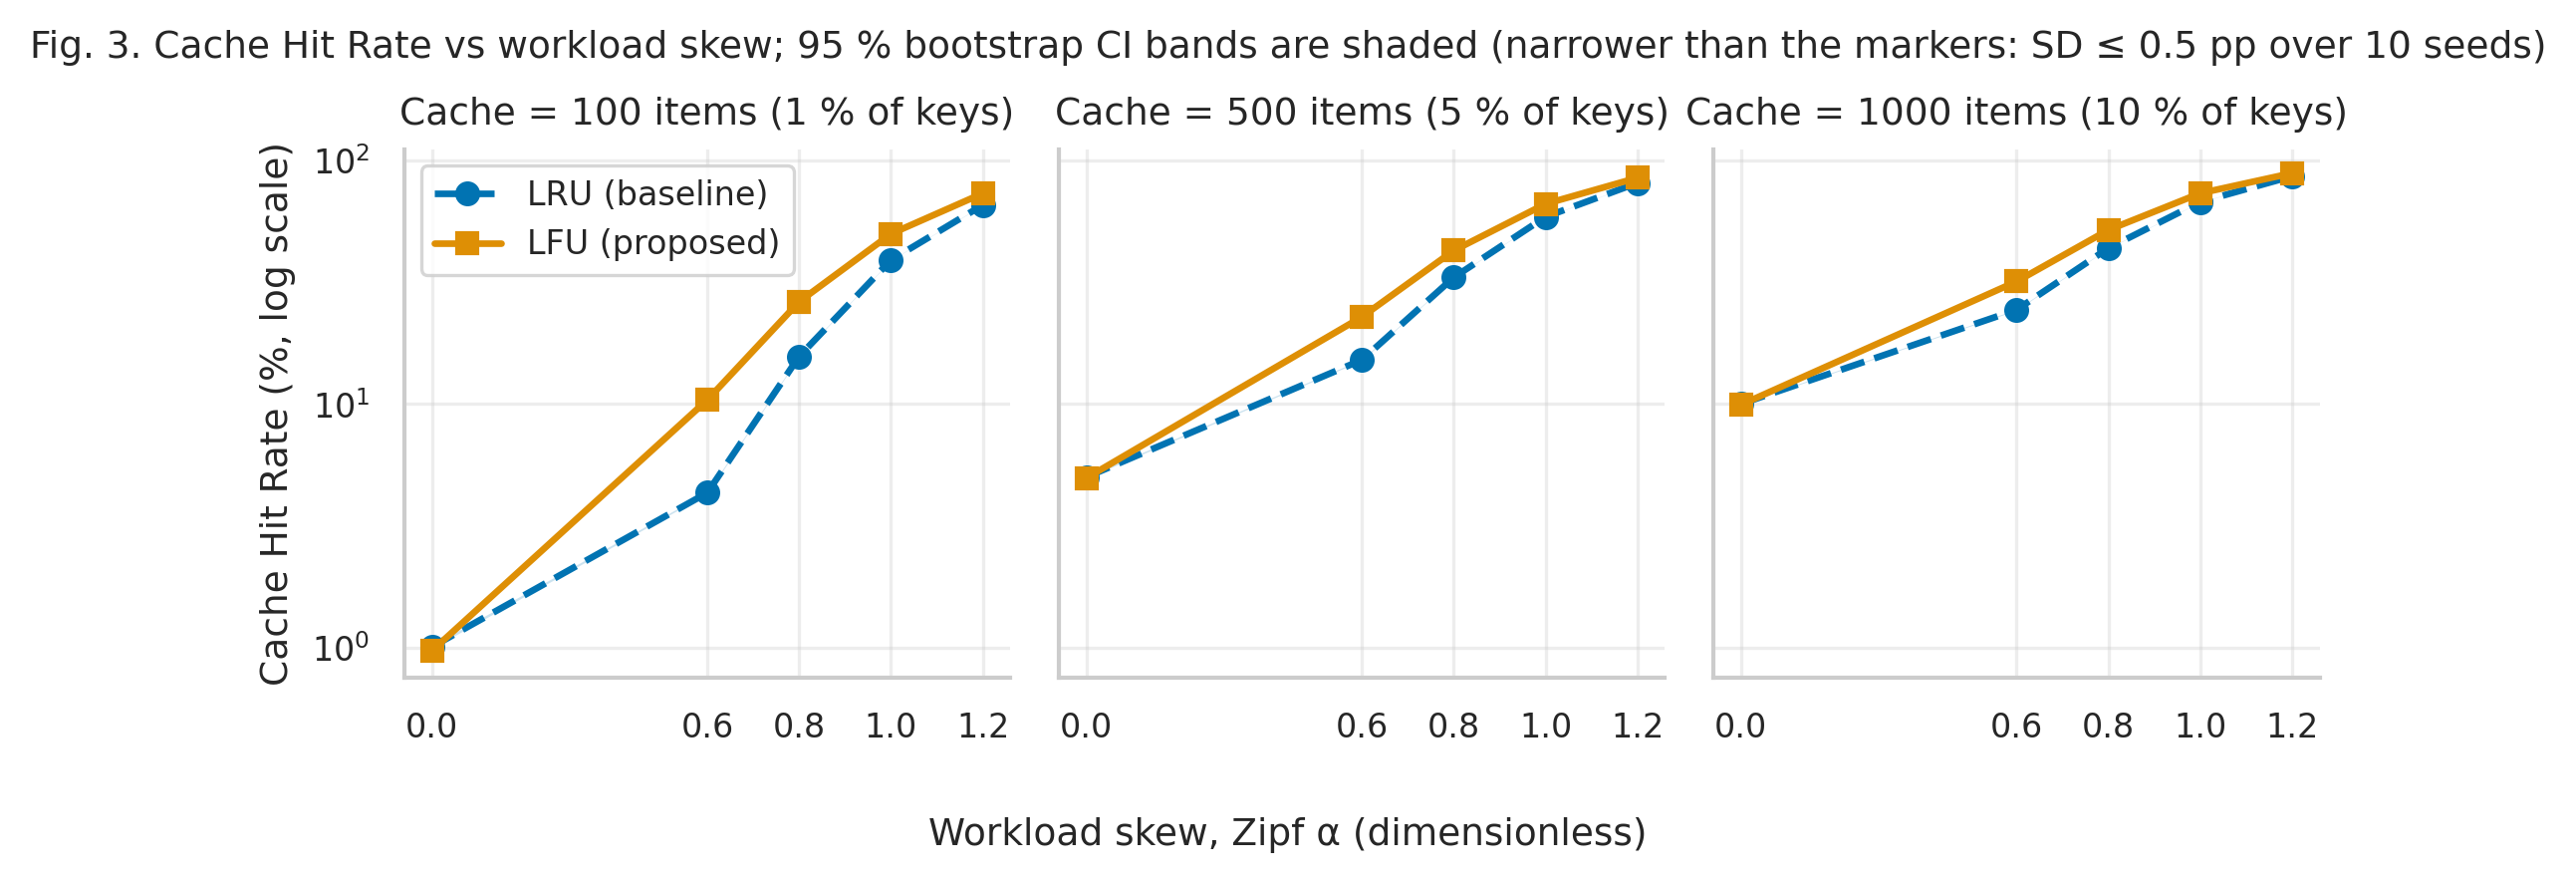

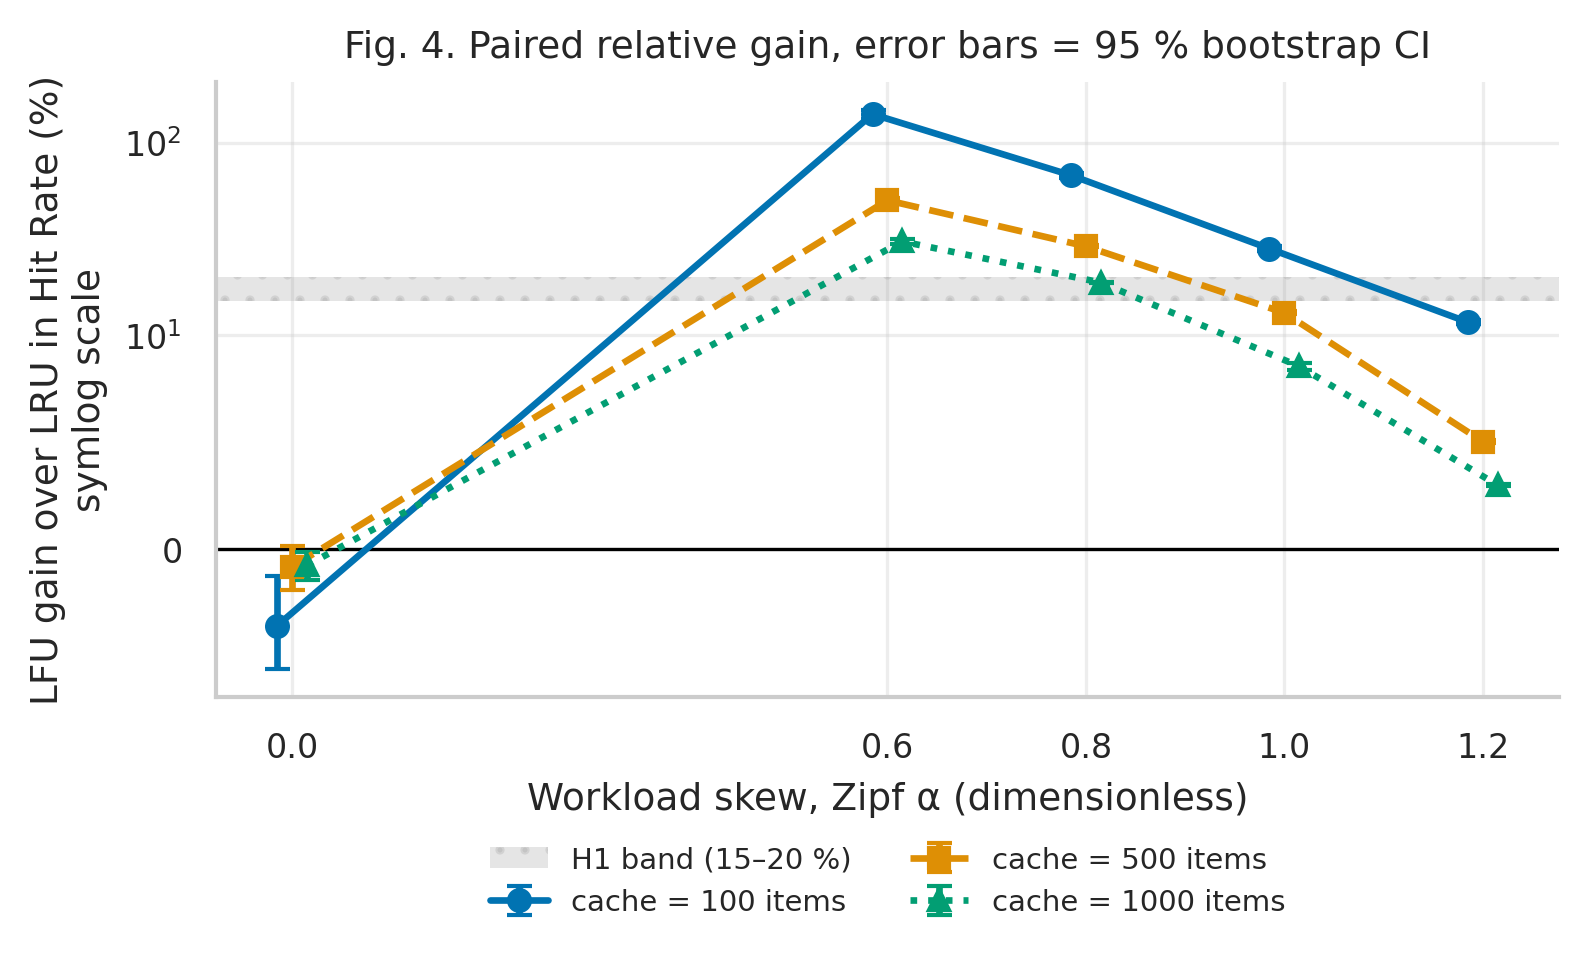

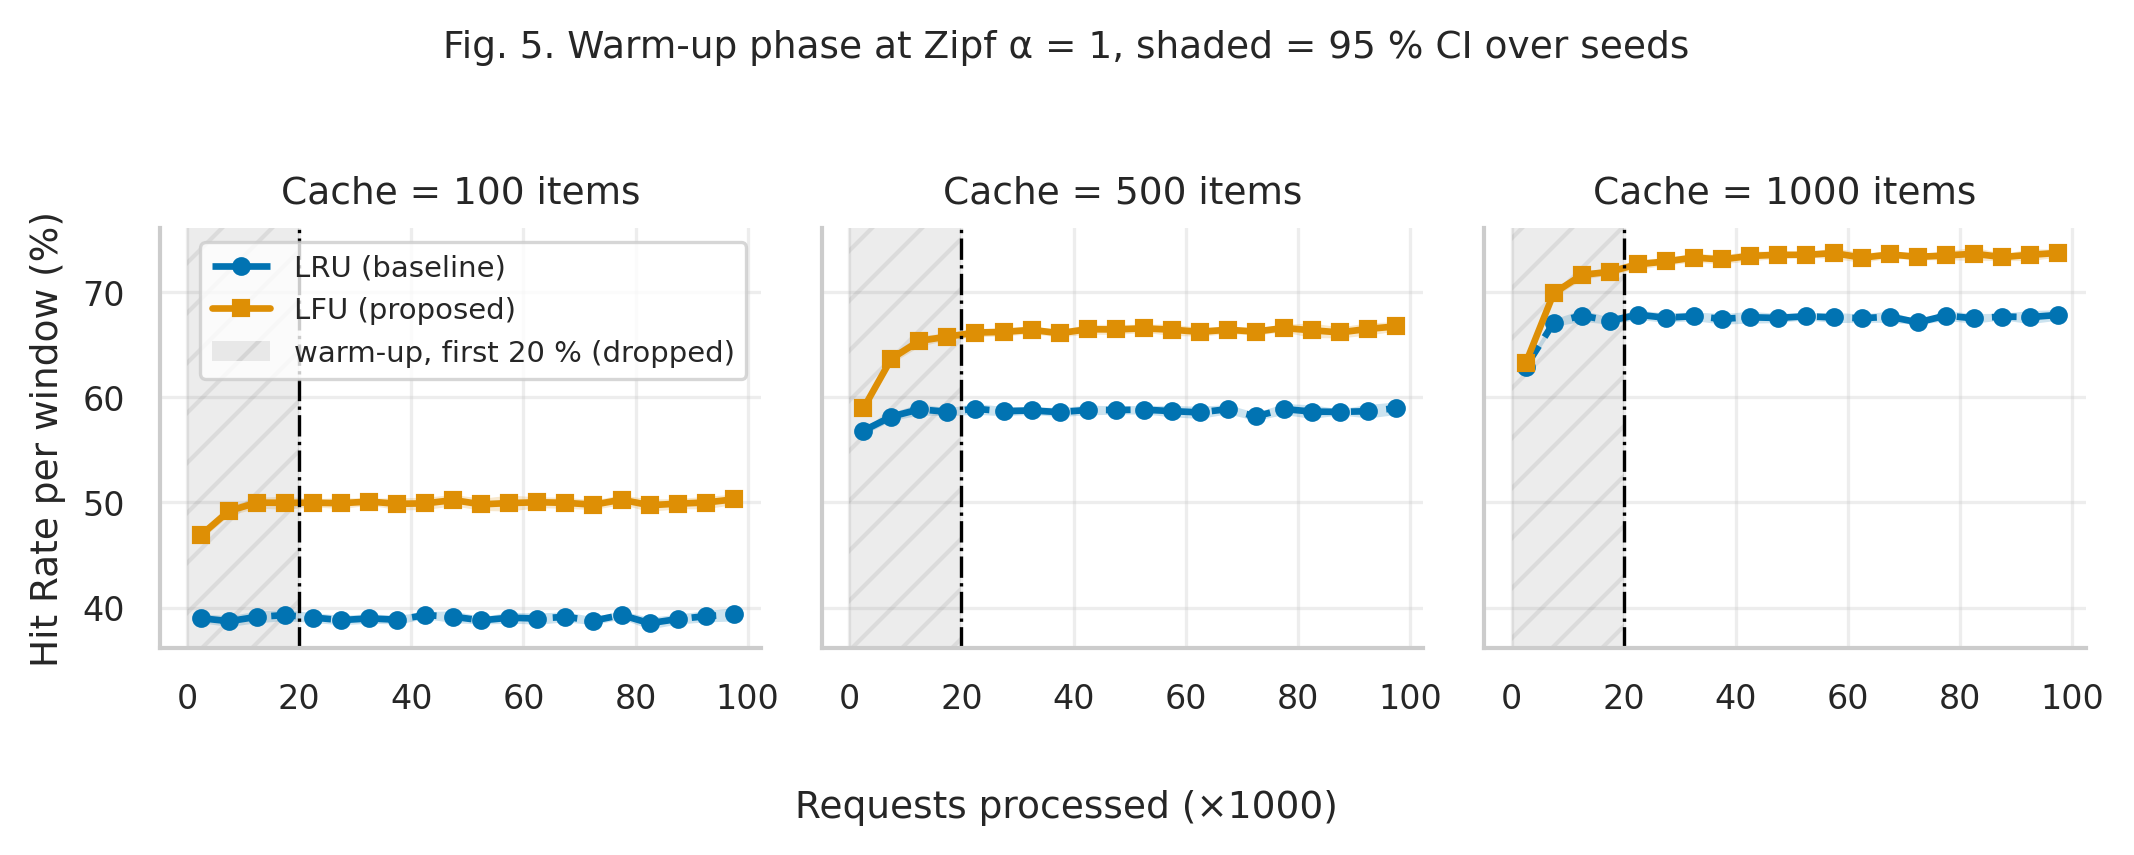

In [16]:
for name in ["fig1_latency_vs_load", "fig2_distribution_boxplot", "fig3_hit_rate_vs_alpha",
             "fig4_relative_gain", "fig5_warmup_phase"]:
    display(Image(filename=str(FIGURES / f"{name}.png"), width=900))

## 8. Выводы

In [17]:
r = summary.set_index(["alpha", "cache_size", "policy"])
g = gains.set_index(["alpha", "cache_size"])
display(Markdown(f'''
* **H1 (α = 1.0, кэш 100):** LFU {r.loc[(1.0, 100, "lfu"), "hit_rate_mean"]:.2f} % vs LRU {r.loc[(1.0, 100, "lru"), "hit_rate_mean"]:.2f} % Hit Rate,
  прирост **{g.loc[(1.0, 100), "rel_gain_pct"]:+.1f} %** [95 % CI {g.loc[(1.0, 100), "rel_gain_ci95_lo"]:.1f}; {g.loc[(1.0, 100), "rel_gain_ci95_hi"]:.1f}] → H0 отвергается;
  эффект даже выше ожидаемого диапазона 15–20 %.
* Преимущество LFU быстро падает с ростом кэша и при α ≥ 1.0: при кэше 1000 и α = 1.2 — лишь {g.loc[(1.2, 1000), "rel_gain_pct"]:+.1f} %.
* Отрицательный контроль (α = 0, равномерная нагрузка): прирост {g.loc[(0.0, 100), "rel_gain_pct"]:+.1f} … {g.loc[(0.0, 1000), "rel_gain_pct"]:+.1f} % — у LFU нет преимущества, как и ожидалось.
* **Задержка:** с in-memory SQLite LFU медленнее на {gains.rel_latency_change_pct.min():.0f}–{gains.rel_latency_change_pct.max():.0f} % (накладные расходы бакетов),
  но при штрафе промаха выше {finite.breakeven_db_penalty_us.max():.0f} µs (любая сетевая БД) LFU становится быстрее.
* **Guardrails:** {guard["errors"]} ошибок на {guard["total_requests"]:,} запросов, нарушений ёмкости — {guard["capacity_violations"]}.
'''))


* **H1 (α = 1.0, кэш 100):** LFU 49.98 % vs LRU 39.02 % Hit Rate,
  прирост **+28.1 %** [95 % CI 27.3; 28.9] → H0 отвергается;
  эффект даже выше ожидаемого диапазона 15–20 %.
* Преимущество LFU быстро падает с ростом кэша и при α ≥ 1.0: при кэше 1000 и α = 1.2 — лишь +3.0 %.
* Отрицательный контроль (α = 0, равномерная нагрузка): прирост -3.6 … -0.8 % — у LFU нет преимущества, как и ожидалось.
* **Задержка:** с in-memory SQLite LFU медленнее на 8–68 % (накладные расходы бакетов),
  но при штрафе промаха выше 17 µs (любая сетевая БД) LFU становится быстрее.
* **Guardrails:** 0 ошибок на 30,000,000 запросов, нарушений ёмкости — 0.
